# Diamond Data Analysis

This notebook analyzes the diamond dataset to understand various characteristics and patterns in diamond properties.

In [2]:
# Import required libraries
import pandas as pd

import seaborn as sns 
import matplotlib.pylab as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.metrics import r2_score 
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import KFold, cross_val_score

### 1. Data Selection
Description of data inclusive

In [5]:
#1. Data Selection
#Import data
data = pd.read_csv("/workspaces/SC5002_Lab_Assignment_2/diamonds.csv")
print(data.head()) #see first 5 rows of data

#This is to confirm whether the file used is correct

   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75


In [4]:
print(data.tail()) #see last 5 rows of data

       carat        cut color clarity  depth  table  price     x     y     z
49995   0.72      Ideal     D     SI1   60.8   57.0   2757  5.75  5.76  3.50
49996   0.72       Good     D     SI1   63.1   55.0   2757  5.69  5.75  3.61
49997   0.70  Very Good     D     SI1   62.8   60.0   2757  5.66  5.68  3.56
49998   0.86    Premium     H     SI2   61.0   58.0   2757  6.15  6.12  3.74
49999   0.75      Ideal     D     SI2   62.2   55.0   2757  5.83  5.87  3.64


In [6]:
#Further exploration of data
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    50000 non-null  float64
 1   cut      50000 non-null  object 
 2   color    50000 non-null  object 
 3   clarity  50000 non-null  object 
 4   depth    50000 non-null  float64
 5   table    50000 non-null  float64
 6   price    50000 non-null  int64  
 7   x        50000 non-null  float64
 8   y        50000 non-null  float64
 9   z        50000 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 3.8+ MB
None


In [7]:
print(data.cut.value_counts())
print(data.color.value_counts())
print(data.clarity.value_counts())

cut
Ideal        19938
Premium      12806
Very Good    11204
Good          4557
Fair          1495
Name: count, dtype: int64
color
G    10452
E     9085
F     8864
H     7711
D     6224
I     5058
J     2606
Name: count, dtype: int64
clarity
SI1     12115
VS2     11404
SI2      8519
VS1      7579
VVS2     4694
VVS1     3369
IF       1632
I1        688
Name: count, dtype: int64


In [8]:
print(data.duplicated().sum()) #check for duplicates

126


In [9]:
print(data.isnull().sum()) #check for any NaN values

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64


In [10]:
print(data[data.y == 0])

       carat        cut color clarity  depth  table  price    x    y    z
11038   1.00  Very Good     H     VS2   63.3   53.0   5139  0.0  0.0  0.0
14731   1.14       Fair     G     VS1   57.5   67.0   6381  0.0  0.0  0.0
22721   1.56      Ideal     G     VS2   62.2   54.0  12800  0.0  0.0  0.0
24336   1.20    Premium     D    VVS1   62.1   59.0  15686  0.0  0.0  0.0
25439   2.25    Premium     H     SI2   62.8   59.0  18034  0.0  0.0  0.0
45910   0.71       Good     F     SI2   64.1   60.0   2130  0.0  0.0  0.0


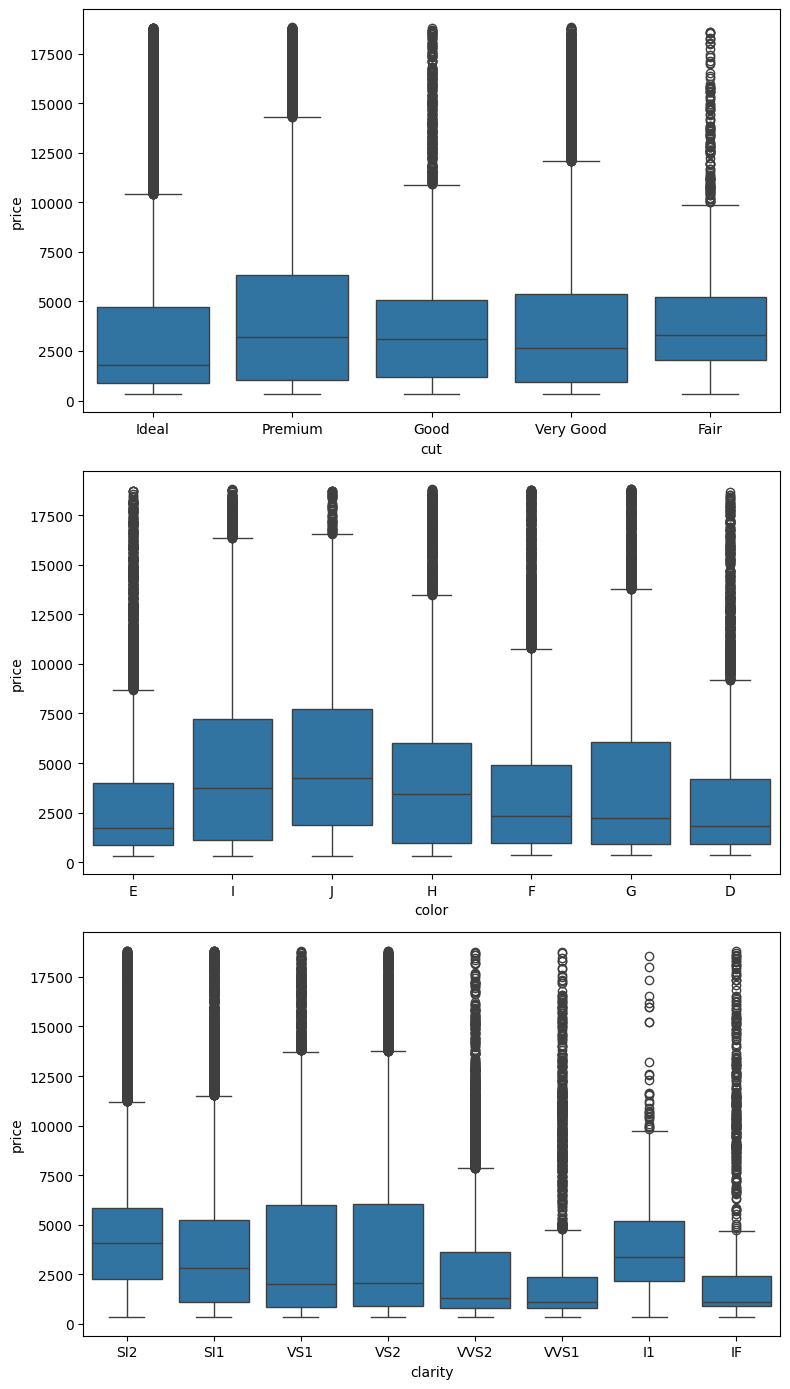

In [11]:
plt.figure(figsize=(8, 14))
plt.subplot(3,1,1)
sns.boxplot(x = 'cut', y = 'price', data = data)
plt.subplot(3,1,2)
sns.boxplot(x = 'color', y = 'price', data = data)
plt.subplot(3,1,3)
sns.boxplot(x = 'clarity', y = 'price', data = data)
plt.tight_layout()
plt.show()

From the boxplots, we observe that cut, color, and clarity do not show straightforward relationships with diamond price. For example, Fair cut and lower color grades (I, J) sometimes show higher median prices than their “better” counterparts. Similarly, diamonds with low clarity (I1) can still command high prices. This suggests that other features, especially carat weight, strongly interact with these variables, and must be considered together in a regression model. Hence, we will have to convert these variables using Label Encoding later.

In [12]:
numerical_columns = [key for key, value in data.dtypes.items()  if value!='O']
corr_matrix = data[numerical_columns].corr()
print(corr_matrix['price'].sort_values(ascending=False))

price    1.000000
carat    0.921804
x        0.884919
y        0.864393
z        0.860963
table    0.129848
depth   -0.012731
Name: price, dtype: float64


From the results, carat has the strongest positive correlation to price, where carat increases, price increases dimensions x y and z also have strong positive correlation to price, since bigger stones, means greater price. On the other hand, depth and table do not determine the price value due to their low correlation